<a href="https://colab.research.google.com/github/Dshah1003/Bank-Simulation-Project-/blob/main/Telecom_2B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Identity Document Fraud Detection**
### Data Exploration

**AI Studio Challenge**  
**Industry Partner:** Verizon  
**Milestone:** September — Binary Classification  
**Dataset:** IDNet Identity Document Analysis Dataset

---



## **1. Project Overview**
The goal of our project is to develop a binary classification model that distinguishes between genuine and fake identity documents in the context of Verizon's customer onboarding process.  

In this notebook, we explore the IDNet dataset and prepare a manageable sample for further analysis.


## **2. Setup**
Import the libraries needed for dataset exploration, image processing, and visualization.

In [18]:
import os
import glob
import shutil
import zipfile
from collections import Counter

import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

## **3. Dataset Exploration**

### 3.1 Upload & extract raw_sample.zip


In [19]:
from google.colab import files
uploaded = files.upload()

Saving raw_sample.zip to raw_sample (2).zip


In [20]:
with zipfile.ZipFile("raw_sample.zip", 'r') as z:
    z.extractall("/content/raw_sample")

print(f"Total files: {len(os.listdir('/content/raw_sample'))}")

Total files: 600


### 3.2 Dataset Structure (counts per category)


In [21]:
raw_dir = "/content/raw_sample"
all_files = os.listdir(raw_dir)

labels = ["drivers_license", "national_id", "passport"]
counts = Counter()
for f in all_files:
    for label in labels:
        if f.startswith(label):
            counts[label] += 1

for k, v in counts.items():
    print(f"{k}: {v} images")
print(f"Total: {sum(counts.values())}")

drivers_license: 200 images
national_id: 200 images
passport: 200 images
Total: 600


### 3.3 Image Properties (formats, dimensions)

In [23]:
formats, sizes, file_sizes_kb = [], [], []

for f in all_files:
    path = os.path.join(raw_dir, f)
    with Image.open(path) as im:
        formats.append(im.format)
        sizes.append(im.size)
    file_sizes_kb.append(os.path.getsize(path) / 1024)

print("Formats:", Counter(formats))
widths, heights = zip(*sizes)
print(f"Width range: {min(widths)}–{max(widths)}")
print(f"Height range: {min(heights)}–{max(heights)}")
print(f"Avg file size: {sum(file_sizes_kb)/len(file_sizes_kb):.1f} KB")

# Break down avg size per category (explains the WV vs RUS/GRC size difference)
for label in labels:
    matching = [f for f in all_files if f.startswith(label)]
    sizes_kb = [os.path.getsize(os.path.join(raw_dir, f)) / 1024 for f in matching]
    print(f"{label}: avg {sum(sizes_kb)/len(sizes_kb):.1f} KB ({len(matching)} images)")

Formats: Counter({'JPEG': 400, 'PNG': 200})
Width range: 1013–1519
Height range: 638–1069
Avg file size: 463.7 KB
drivers_license: avg 980.9 KB (200 images)
national_id: avg 199.9 KB (200 images)
passport: avg 210.5 KB (200 images)


### 3.4 Visualize sample genuine images

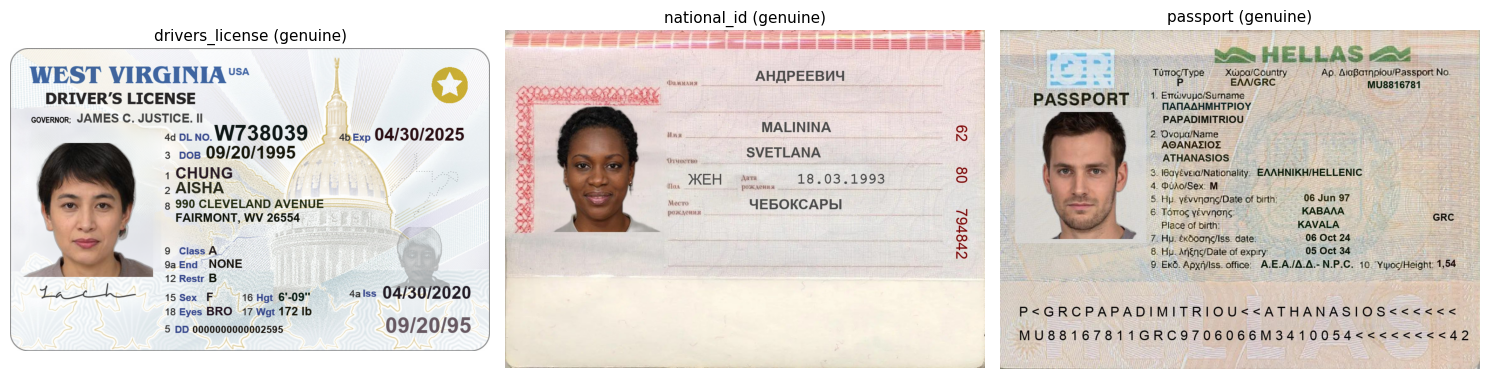

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, labels):
    matching = [f for f in all_files if f.startswith(label)]
    img = Image.open(os.path.join(raw_dir, matching[0]))
    ax.imshow(img)
    ax.set_title(f"{label} (genuine)", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

## **4. Synthetic Fake Generation**
### 4.1 Apply Gaussian blur to create fake subset

In [25]:
import random
random.seed(42)
np.random.seed(42)

def add_noise(img, sigma):
    noise = np.random.normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def camera_variation(img):
    """Light, realistic changes for some genuine images."""
    if random.random() < 0.5:
        img = cv2.GaussianBlur(img, (3, 3), 0)
    img = cv2.convertScaleAbs(img, alpha=random.uniform(0.9, 1.1), beta=random.randint(-15, 15))
    return add_noise(img, random.uniform(0, 8))

def make_fake(img):
    k = random.choice([5, 9, 15, 21])          # varied blur strength
    if random.random() < 0.5:                  # half: blur whole image
        out = cv2.GaussianBlur(img, (k, k), 0)
        kind = "full"
    else:                                      # half: blur one region only
        h, w = img.shape[:2]
        rh, rw = int(h * random.uniform(0.2, 0.4)), int(w * random.uniform(0.2, 0.4))
        y, x = random.randint(0, h - rh), random.randint(0, w - rw)
        out = img.copy()
        out[y:y+rh, x:x+rw] = cv2.GaussianBlur(img[y:y+rh, x:x+rw], (k, k), 0)
        kind = "partial"
    return add_noise(out, random.uniform(3, 15)), f"{kind}{k}"

output_dir = "/content/final_sample"
shutil.rmtree(output_dir, ignore_errors=True)
os.makedirs(output_dir, exist_ok=True)

for label in labels:
    matching = sorted(f for f in all_files if f.startswith(label))
    genuine_files = matching[:100]
    to_blur_files = matching[100:200]

    for f in genuine_files:
        img = cv2.imread(os.path.join(raw_dir, f))
        if random.random() < 0.3:              # 30% of genuines get camera variation
            img = camera_variation(img)
        cv2.imwrite(os.path.join(output_dir, f"{label}_genuine_{f}"), img)

    for f in to_blur_files:
        img = cv2.imread(os.path.join(raw_dir, f))
        fake, tag = make_fake(img)
        cv2.imwrite(os.path.join(output_dir, f"{label}_fake_{tag}_{f}"), fake)

print(f"Total in final_sample: {len(os.listdir(output_dir))}")

Total in final_sample: 600


### 4.2 Visualize genuine vs. fake side-by-side

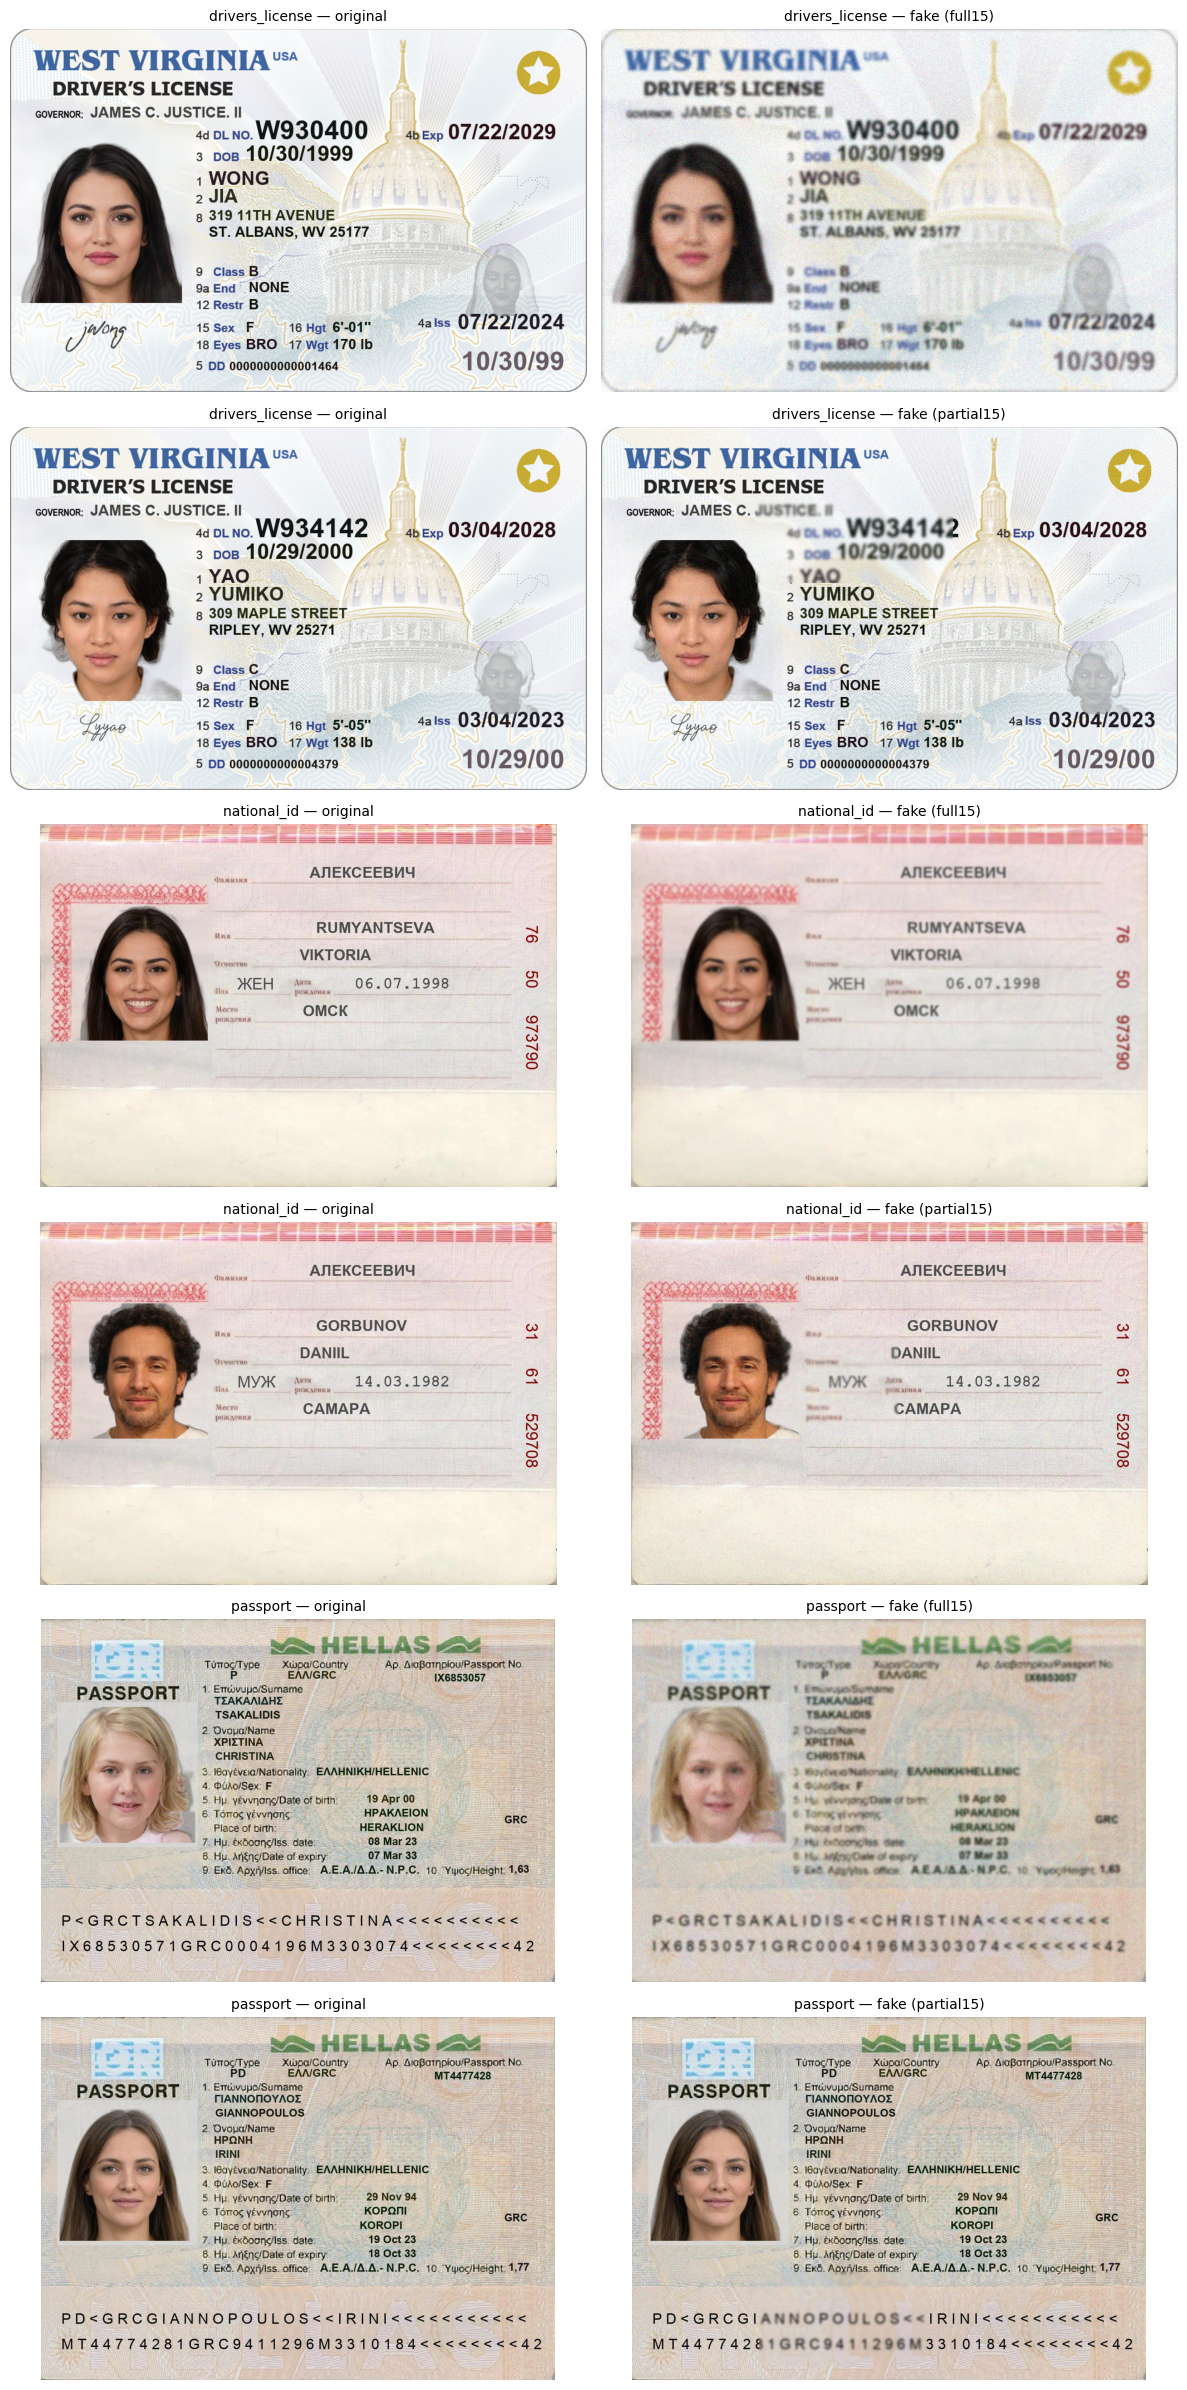

In [26]:
fake_files = sorted(f for f in os.listdir(output_dir) if "_fake_" in f)

fig, axes = plt.subplots(6, 2, figsize=(12, 24))
row = 0
for label in labels:
    for kind in ["full", "partial"]:
        f = next(x for x in fake_files if x.startswith(f"{label}_fake_{kind}"))
        tag, original_name = f[len(f"{label}_fake_"):].split("_", 1)

        original = cv2.imread(os.path.join(raw_dir, original_name))
        fake = cv2.imread(os.path.join(output_dir, f))

        axes[row, 0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
        axes[row, 0].set_title(f"{label} — original", fontsize=10)
        axes[row, 1].imshow(cv2.cvtColor(fake, cv2.COLOR_BGR2RGB))
        axes[row, 1].set_title(f"{label} — fake ({tag})", fontsize=10)
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")
        row += 1

plt.tight_layout()
plt.show()

### 4.3 Confirm final_sample: 600 total, labeled genuine/fake

In [27]:
final_files = os.listdir(output_dir)
final_counts = Counter()

for f in final_files:
    for label in labels:
        for kind in ["genuine", "fake"]:
            if f.startswith(f"{label}_{kind}"):
                final_counts[f"{label}_{kind}"] += 1

for k, v in final_counts.items():
    print(f"{k}: {v}")
print(f"Total: {sum(final_counts.values())}")

drivers_license_genuine: 100
national_id_fake: 100
passport_genuine: 100
national_id_genuine: 100
passport_fake: 100
drivers_license_fake: 100
Total: 600


**Feature extraction (HOG + LBP)**

In [28]:
from skimage.feature import hog, local_binary_pattern

IMG_SIZE = (512, 320)  # (width, height)

def extract_features(path):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, IMG_SIZE, interpolation=cv2.INTER_AREA)

    # HOG: edge directions across the document
    hog_vec = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))

    # LBP: texture histograms on a 4x4 grid, so a blurred region shows up locally
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    h, w = lbp.shape
    lbp_vec = []
    for i in range(4):
        for j in range(4):
            cell = lbp[i*h//4:(i+1)*h//4, j*w//4:(j+1)*w//4]
            hist, _ = np.histogram(cell, bins=10, range=(0, 10), density=True)
            lbp_vec.extend(hist)

    return np.concatenate([hog_vec, lbp_vec])

files = sorted(os.listdir(output_dir))
X = np.array([extract_features(os.path.join(output_dir, f)) for f in files])
y = np.array([1 if "_fake_" in f else 0 for f in files])          # 1 = fake, 0 = genuine
doc_type = np.array([next(l for l in labels if f.startswith(l)) for f in files])

print("Feature matrix:", X.shape)
print("Fake:", y.sum(), "| Genuine:", len(y) - y.sum())

Feature matrix: (600, 21364)
Fake: 300 | Genuine: 300


***Train / Test Split (80-20)***

In [29]:
from sklearn.model_selection import train_test_split

strata = [f"{d}_{l}" for d, l in zip(doc_type, y)]
X_train, X_test, y_train, y_test, f_train, f_test = train_test_split(
    X, y, np.array(files), test_size=0.2, stratify=strata, random_state=42
)
print("Train:", len(y_train), "| Test:", len(y_test))

Train: 480 | Test: 120


In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=42)),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name}: trained")

Logistic Regression: trained
SVM (RBF): trained
Random Forest: trained


Logistic Regression  acc 0.925 | prec 0.932 | rec 0.917 | F1 0.924 | AUC 0.984
SVM (RBF)            acc 0.942 | prec 0.921 | rec 0.967 | F1 0.943 | AUC 0.983
Random Forest        acc 0.950 | prec 0.922 | rec 0.983 | F1 0.952 | AUC 0.987


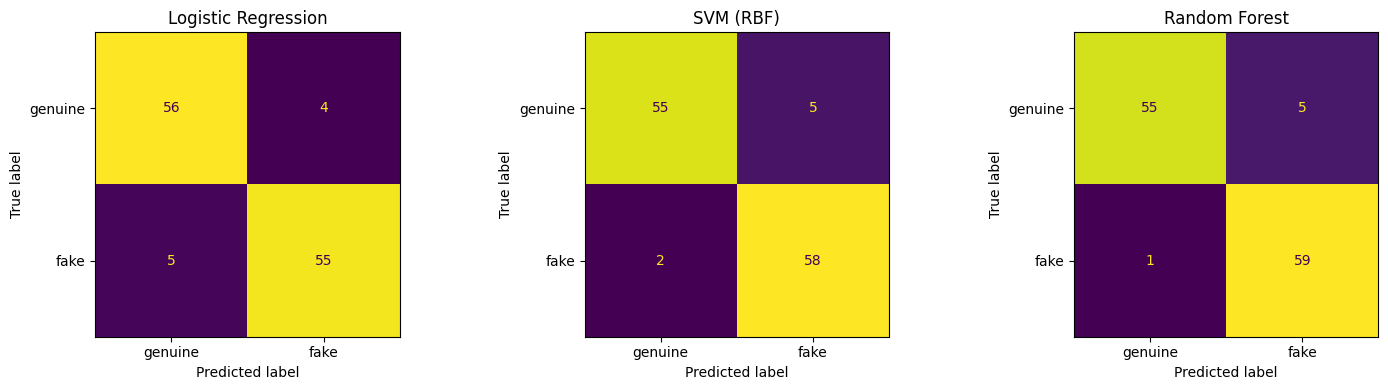

In [31]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    print(f"{name:20s} acc {accuracy_score(y_test, pred):.3f} | "
          f"prec {precision_score(y_test, pred):.3f} | rec {recall_score(y_test, pred):.3f} | "
          f"F1 {f1_score(y_test, pred):.3f} | AUC {roc_auc_score(y_test, prob):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test,
                                          display_labels=["genuine", "fake"],
                                          ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [32]:
for name, m in models.items():
    pred = m.predict(X_test)
    for kind in ["full", "partial"]:
        mask = np.array([f"_fake_{kind}" in f for f in f_test])
        print(f"{name:20s} {kind:8s} fakes caught: {pred[mask].mean():.0%} ({mask.sum()} images)")

Logistic Regression  full     fakes caught: 97% (33 images)
Logistic Regression  partial  fakes caught: 85% (27 images)
SVM (RBF)            full     fakes caught: 100% (33 images)
SVM (RBF)            partial  fakes caught: 93% (27 images)
Random Forest        full     fakes caught: 100% (33 images)
Random Forest        partial  fakes caught: 96% (27 images)


In [34]:
def predict_image(path):
    feats = extract_features(path).reshape(1, -1)
    results = []
    for name, m in models.items():
        p = m.predict_proba(feats)[0, 1]          # probability of fake
        verdict = "FAKE" if p >= 0.5 else "GENUINE"
        results.append(f"{name}: {verdict} ({p:.0%} fake)")
    return results

Saving national_id_027.png to national_id_027.png
national_id_027.png
  Logistic Regression  GENUINE  genuine 100% | fake 0%
  SVM (RBF)            GENUINE  genuine 99% | fake 1%
  Random Forest        GENUINE  genuine 100% | fake 0%
  FINAL (average)      GENUINE  genuine 100% | fake 0%


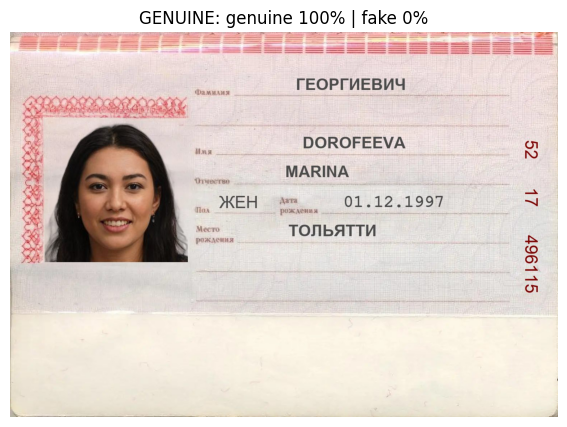

In [36]:
from google.colab import files

uploaded = files.upload()

for name in uploaded:
    path = f"/content/{name}"
    if cv2.imread(path) is None:
        print(f"{name}: couldn't read it. Use a .jpg or .png file.")
        continue

    feats = extract_features(path).reshape(1, -1)
    probs = {}
    print(name)
    for model_name, m in models.items():
        p_fake = m.predict_proba(feats)[0, 1]
        probs[model_name] = p_fake
        verdict = "FAKE" if p_fake >= 0.5 else "GENUINE"
        print(f"  {model_name:20s} {verdict:8s} genuine {1 - p_fake:.0%} | fake {p_fake:.0%}")

    avg = np.mean(list(probs.values()))
    final = "FAKE" if avg >= 0.5 else "GENUINE"
    print(f"  FINAL (average)      {final:8s} genuine {1 - avg:.0%} | fake {avg:.0%}")

    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
    plt.title(f"{final}: genuine {1 - avg:.0%} | fake {avg:.0%}")
    plt.axis("off")
    plt.show()